Name Muhtasim Haque Nahian

Labpartner(s) Taherunnesa Rahi

In [26]:
#import statements go here
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from itertools import combinations
from collections import Counter

# Class 9.2

For the lab you will integrate zotero into word, google docs, and optionally LaTeX.

Reminder your final project proposal is due Sunday. On Monday you will pitch your final project proposal to the class


**W.1** Make a map of the Gulf Coast in Cartopy, and figure our how to add rivers and state boundaries. Add a marker for Baton Rouge.

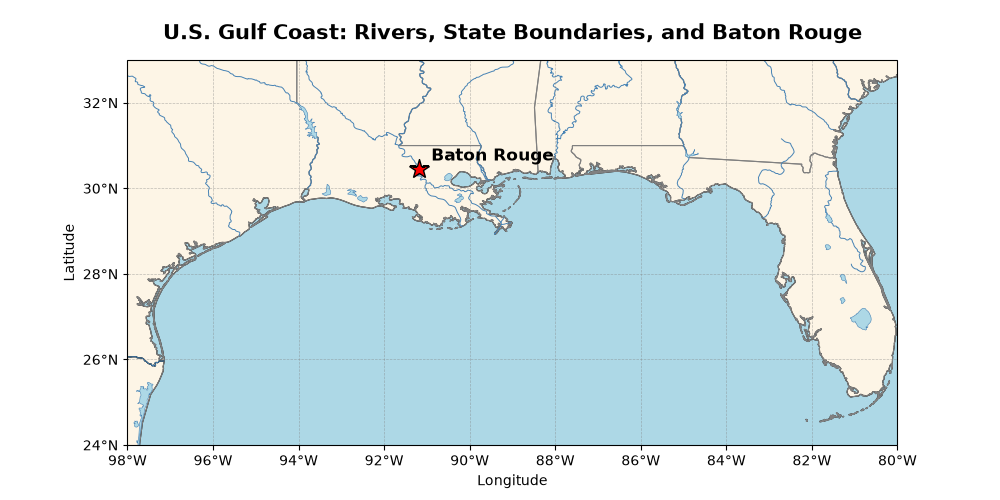

In [49]:
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={"projection": ccrs.PlateCarree()})

ax.set_extent([-98, -80, 24, 33], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="oldlace")
ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="lightblue")
ax.coastlines(resolution="10m", linewidth=0.8)

# State and international boundaries
ax.add_feature(cfeature.STATES.with_scale("10m"), edgecolor="gray", linewidth=0.8)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="black", linewidth=0.8)

# Rivers and lakes
ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="steelblue", linewidth=0.7)
ax.add_feature(cfeature.LAKES.with_scale("10m"), facecolor="lightblue", edgecolor="steelblue", linewidth=0.4)

# Baton Rouge
ax.plot(-91.1871, 30.4515, marker="*", markersize=15, color="red", markeredgecolor="black", transform=ccrs.PlateCarree(), zorder=5)
ax.text(-90.9, 30.65, "Baton Rouge", fontsize=12, fontweight="bold", transform=ccrs.PlateCarree(), zorder=6)


ax.set_xticks(range(-98, -79, 2), crs=ccrs.PlateCarree())
ax.set_yticks(range(24, 34, 2), crs=ccrs.PlateCarree())
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.grid(color="gray", linestyle="--", linewidth=0.5, alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("U.S. Gulf Coast: Rivers, State Boundaries, and Baton Rouge", fontsize=15, fontweight="bold", pad=15)

plt.show()

**W.2** Do some more work on the Chipotle data from Monday

In [21]:
chipo = pd.read_csv("https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv", sep="\t")
chipo["item_price"] = (chipo["item_price"].str.replace("$", "", regex=False).str.strip().astype(float))
chipo.head()

,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,2.39
1,1,1,Izze,[Clementine],3.39
2,1,1,Nantucket Nectar,[Apple],3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",16.98


### Which items are most frequently purchased together?

In [29]:
# Find the unique items in each order
order_items = chipo.groupby("order_id")["item_name"].agg(lambda items: sorted(set(items)))
print(order_items)

order_id
1       [Chips and Fresh Tomato Salsa, Chips and Tomat...
2                                          [Chicken Bowl]
3                           [Chicken Bowl, Side of Chips]
4                       [Steak Burrito, Steak Soft Tacos]
5                    [Chips and Guacamole, Steak Burrito]
                              ...                        
1830                      [Steak Burrito, Veggie Burrito]
1831                [Bottled Water, Carnitas Bowl, Chips]
1832            [Chicken Soft Tacos, Chips and Guacamole]
1833                                      [Steak Burrito]
1834                                 [Chicken Salad Bowl]
Name: item_name, Length: 1834, dtype: object


,Item 1,Item 2,Orders together
0,Chicken Bowl,Chips and Guacamole,149
1,Chicken Bowl,Chips,122
2,Chicken Burrito,Chips and Guacamole,114
3,Canned Soft Drink,Chicken Bowl,111
4,Chips and Guacamole,Steak Burrito,76
5,Chicken Burrito,Steak Burrito,72
6,Canned Soft Drink,Chicken Burrito,71
7,Bottled Water,Chicken Bowl,69
8,Chicken Bowl,Chicken Burrito,66
9,Canned Soft Drink,Chips and Guacamole,62


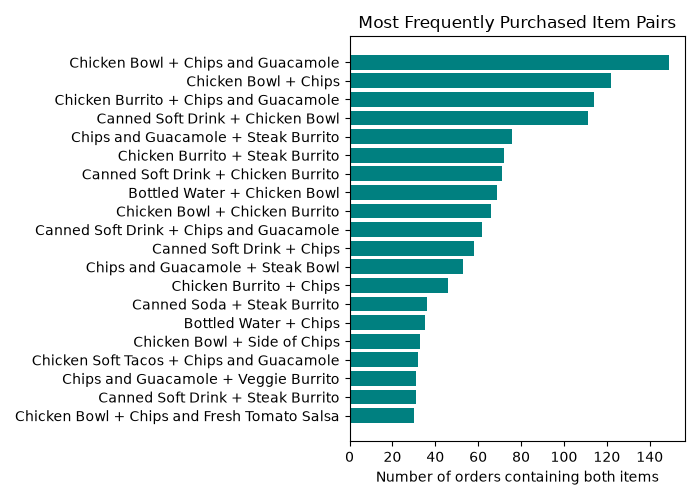

In [41]:
# Count pairs across orders
pair_counts = Counter()

for items in order_items:
    pair_counts.update(combinations(items, 2))

top_pairs = pd.DataFrame([(a, b, count) for (a, b), count in pair_counts.most_common(20)], columns=["Item 1", "Item 2", "Orders together"])
display(top_pairs)

labels = top_pairs["Item 1"] + " + " + top_pairs["Item 2"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(labels[::-1], top_pairs["Orders together"][::-1], color="teal")
ax.set(title="Most Frequently Purchased Item Pairs", xlabel="Number of orders containing both items", ylabel="")
plt.tight_layout()
plt.show()

### Does the average cost per item change with order size?

,number_of_orders,mean_bill,median_cost_per_unit
size_group,,,
1–2 items,1094,15.06,7.10
3–4 items,634,20.67,6.25
5–6 items,74,33.05,6.01
7+ items,32,77.42,6.51


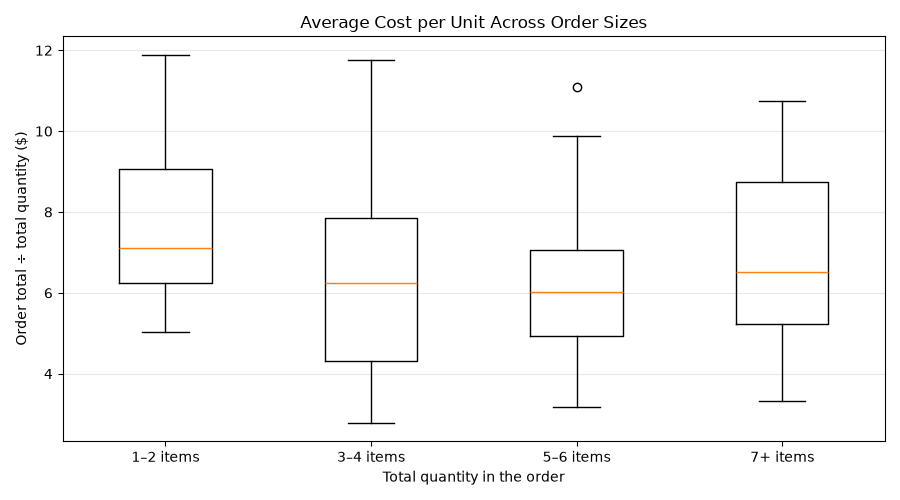

In [43]:
order_size = (chipo.groupby("order_id").agg(total_quantity=("quantity", "sum"), total_spent=("item_price", "sum")))

order_size["cost_per_unit"] = (order_size["total_spent"] / order_size["total_quantity"])

order_size["size_group"] = pd.cut(order_size["total_quantity"], bins=[0, 2, 4, 6, float("inf")],
    labels=["1–2 items", "3–4 items", "5–6 items", "7+ items"])

size_summary = (order_size.groupby("size_group", observed=True).agg(number_of_orders=("total_spent", "size"),
        mean_bill=("total_spent", "mean"), median_cost_per_unit=("cost_per_unit", "median")))

display(size_summary.round(2))

groups = [order_size.loc[order_size["size_group"] == label, "cost_per_unit"]
    for label in size_summary.index
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(groups)
ax.set_xticks(range(1, len(size_summary) + 1))
ax.set_xticklabels(size_summary.index)
ax.set(title="Average Cost per Unit Across Order Sizes", xlabel="Total quantity in the order", ylabel="Order total ÷ total quantity ($)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Lecture 9.2

### Agenda:

- Questions
- Intro to Zotero

### Questions

# Lab 9.2

**E.0** Complete the previous labs if you are behind.

**E.1** Install Zotero and the plugins for your web browser (Chrome or Firefox suggested), Word, and Google docs. Use Zotero to grab a 2-3 citations from the web (e.g., from a scientific journal article web page), then cite them in both Word and Google docs in a sentance or two, then add a Bibliography using zotero.

In Moodle, turn in your word document, a screenshot of your google doc, and a screenshot of your zotero library.

**E.3** Complete your final project proposal and submit it in Moodle

**E.4** Prepare a 5 min presentation of your project proposal, including a brief introduction, your research plan, the programming methods you are planning to use, your preliminary results/plots, and your timeline for completion. ​You will present this in class next Monday.

A good target length is 1 slide per minute.

Upload your talk here: https://lsu.box.com/s/jc4x0p5mu7u1tst38m98i0t1e35z2mfl


**B.1** Bonus! Integrate zotero and overleaf. Note to have the zotero plugin for overleaf you have to pay them. However, you can export a .bib style bibliography for LaTeX and load it into overleaf. If you are extra, go for it! Submit a pdf of your LaTeX document with citations and bibliography, and a screenshot of your .bib file

**Notes** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.